# EEG Preprocessing simf10

This notebook processes iEEG data from the INTRA dataset. The recordings capture 200 epochs of epilesptic spikes.

## 🧪 - Experiment setup
- `ieeg`: 'raw' iEEG.

In [15]:
%matplotlib widget
import mindmap as mm

# reader
dm = mm.io.TutoManager("../../config.yml")
sr = dm.get_subject("intra-12")

# data
ieeg = sr.load("ieeg", task="spk")
src = sr.load("src")

## 🧬 - Data Processing
From Epochs to Average

In [16]:
iave = ieeg.average()

Estimate spike extent and spurious area

In [ ]:
# estimate spike generation extent zone and spurious zone
extent_mask = mm.core.get_spike_extent_mask(
    iave.data.T, 
    perc_max_amp=0.7
)

spurious_mask = mm.core.get_spurious_mask(
    extent_mask,
    mm.analysis.eeg.get_ch_positions(iave),
    spurious_dist=0.01
)

## 📊 - Visualization

Timeseries

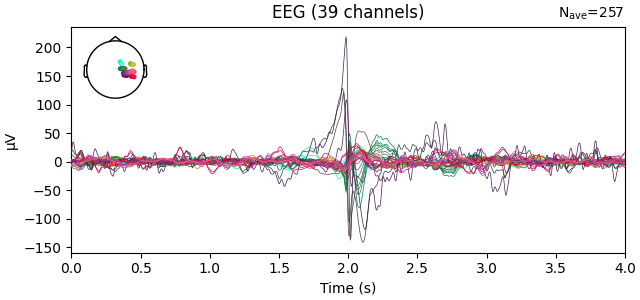

In [ ]:
iave.plot();

Channel positions

In [ ]:
mm.viz.plot_ieeg(
    src,
    mm.analysis.eeg.normalize_evoked_by_baseline(iave, [0,1.0]),
    ts_params={"absolute":True}
).show()

Widget(value='<iframe src="http://localhost:40683/index.html?ui=P_0x78036d5aa750_5&reconnect=auto" class="pyvi…

(10,)

In [ ]:
import mne
import numpy as np

def estimate_evoked_snr(
    evoked: mne.Evoked,
    baseline: tuple[float, float],
    noise_cov: mne.Covariance=None,
    method: str="power",
)-> tuple[np.ndarray, np.ndarray]:
    """
    Compute sensor-space SNR time course from an evoked response.

    Parameters
    ----------
    evoked: mne.Evoked
        Evoked data.

    baseline: tuple[float, float]
        Time window (s) for noise estimate.

    noise_cov: mne.Covariance, optional
        If provided, data is whitened before SNR estimation, making 
        the result consistent with MNE's regularization framework.
    
    method: str ['power', 'variance']
        Whether to use power-based or variance-based 
        estimate.

    Returns
    -------
    snr, snr_db: tuple[np.ndarray, np.ndarray] of shapes (n_times,)
    """
    data = evoked.data
    if noise_cov is not None:
        whitener, _ = mne.cov.compute_whitener(noise_cov, evoked.info, pca=False)
        data = whitener @ data

    b_start, b_stop = evoked.time_as_index(baseline)
    return estimate_snr(data, (b_start, b_stop), method=method)


def estimate_snr(
    timeserie: np.ndarray,
    baseline: tuple[int, int],
    method: str="power",
) -> tuple[np.ndarray, np.ndarray]:
    """
    Computes time-varying SNR relative to a baseline window.

    Parameters
    ----------
    timeserie: np.ndarray of shape (n_samples, n_timepoints)
        Timeseries.

    baseline: tuple[int,int]
        Indices [start, stop) for the noise window.

    method: str ['power', 'variance']
        Whether to use power-based or variance-based 
        estimate.

    Returns
    -------
    snr, snr_db: tuple[np.ndarray, np.ndarray] of shapes (n_times,)
    """
    b_start, b_stop = baseline

    if method == "power":
        noise_power = np.mean(timeserie[:, b_start:b_stop] ** 2)
        signal_power = np.mean(timeserie ** 2, axis=0)
    elif method == "variance":
        noise_power = np.var(timeserie[:, b_start:b_stop])
        signal_power = np.var(timeserie, axis=0)
    else:
        raise ValueError(f"Unknown method '{method}'. Expected 'power' or 'variance'.")

    snr = signal_power / noise_power
    snr_db = 10 * np.log10(snr)
    return snr, snr_db

from mindmap.analysis.functional.eeg.utils import same_evoked
from mindmap.core.metric import calc_correlation


def compute_evoked_correlation(
    evoked_ref: mne.Evoked,
    evoked_est: mne.Evoked,
    method: str = "pearson",
    axis: int | None = None,
    average: bool = False,
) -> np.ndarray | float:
    """
    Compute correlation between two evoked objects.

    Parameters
    ----------
    evoked_ref: mne.Evoked
        Reference activity (e.g. True iEEG).

    evoked_est: mne.Evoked
        Estimated activity (e.g. virtual iEEG).

    method: str ['pearson', 'spearman', 'log-envelope']
        Correlation method.

    axis: int or None
        Axis along which to compute correlation.
        - None: spatio-temporal scalar
        - 0: spatial correlation per timepoint -> (n_timepoints,)
        - 1: temporal correlation per channel -> (n_channels)
    
    average: bool
        If True, return the mean over the result vector.

    Returns
    -------
    corr: float or np.ndarray
        Correlation value(s). Shape depends on axis and average.
    """
    if not same_evoked(evoked_ref, evoked_est):
        raise ValueError("Evokeds must have same channels and timepoints.")
    
    corr = calc_correlation(
        evoked_ref.data, evoked_est.data, method=method, axis=axis,
    )
    return np.mean(corr) if average else corr



In [ ]:
import mindmap as mm
from bids import BIDSLayout

dm = mm.io.TutoManager("../../config.yml")
sr = dm.get_subject("simf10")

sr.get_path()

In [ ]:
config = "/home/nino/Code/mindmap/mindmap/resources/pybids_config.json"

layout = BIDSLayout(
    root = dm.roots["raw"],
    derivatives = dm.roots["mm"],
    config = ["bids", "derivatives", config],
)


None


In [ ]:
layout = BIDSLayout(
    root = dm.roots["raw"]
)
layout.add_derivatives(
    dm.roots["mm"],
    
    config = config,
)

In [87]:
source = {"subject":"simf10", "suffix":"T1w"}
layout.build_path(source, scope="mindmap", validate=False)

ValueError: Unable to construct build path with source {'subject': 'simf10', 'suffix': 'T1w'}

In [52]:


layouts = layout._get_layouts_in_scope("mindmap")
path_patterns = []
seen_configs = set()
for l in layouts:
    for c in l.config.values():
        if c in seen_configs:
            continue
        if c.default_path_patterns is not None:
            path_patterns.extend(c.default_path_patterns)
        seen_configs.add(c)

In [62]:
for l in layouts:
    print(l.config)
    for c in l.config.values():
        print(c)

{'bids': <Config bids>, 'derivatives': <Config derivatives>}
<Config bids>
<Config derivatives>


In [ ]:
for c in layout.config["mindmap"]

TypeError: 'Config' object is not iterable